# EARLIEST Synthetic Baseline Analysis

## Research objective

This notebook analyses the accuracy–earliness trade-off of the original EARLIEST algorithm on its synthetic benchmark.

The earliness parameter $\lambda$ is varied between 0.00 and 0.15 in increments of 0.01. Each configuration is independently trained and evaluated using three random seeds (42, 123 and 456), producing 48 experimental runs.

### Research questions

1. How does increasing $\lambda$ affect classification accuracy?
2. How does increasing $\lambda$ affect the proportion of the input sequence observed before classification?
3. How sensitive are the results to random initialisation?
4. Do the observed trends reproduce the qualitative findings of Hartvigsen et al. (2019)?

### Evaluation metrics

- **Testing accuracy:** Proportion of correctly classified test examples.
- **Mean proportion used:** Percentage of the input sequence observed before the model stops.
- **Variability:** Sample standard deviation across the three experimental seeds.

The purpose is to establish an interpretable baseline before introducing physiological data and signal-quality-aware stopping policies.

0. Import libraries

In [11]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
SRC_DIR = PROJECT_ROOT / "src"
RESULTS_DIR = PROJECT_ROOT / 'results'
FIGURES_DIR = PROJECT_ROOT / 'figures'

FIGURES_DIR.mkdir(parents = True, exist_ok = True)
print(f"Project root: {PROJECT_ROOT}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Project root: C:\Users\benjo\Documents\Projects\rl_project\EARLIEST


1. Load raw experimental results

In [12]:
csv_path = RESULTS_DIR / "synthetic_baseline.csv"

df = pd.read_csv(csv_path)

print("Number of experiments:", len(df))
print("Columns:", df.columns.tolist())

display(df.head(10))

Number of experiments: 48
Columns: ['lambda', 'seed', 'test_accuracy', 'mean_proportion_used_percent']


,lambda,seed,test_accuracy,mean_proportion_used_percent
0,0.00,42,1.00,76.726997
1,0.00,123,0.96,81.091003
2,0.00,456,0.94,75.818001
3,0.01,42,0.90,49.636002
4,0.01,123,0.90,61.272999
5,0.01,456,0.84,58.909000
6,0.02,42,0.80,41.636002
7,0.02,123,0.72,46.363998
8,0.02,456,0.72,44.181999
9,0.03,42,0.72,27.455000


2. Statistic Calculations

In [ ]:
analysis_df = df.copy()

analysis_df['accuracy_percent'] = (analysis_df['test_accuracy']*100)

summary = (analysis_df.groupby('lambda',as_index = False).agg(
    accuracy_mean = ('accuracy_percent','mean'),
    accuracy_std= ('accuracy_percent','std'),
    observed_mean = ('mean_proportion_used_percent','mean'),
    observed_std = ('mean_proportion_used_percent','std'),
    n_runs = ('seed','count')).sort_values('lambda'))

display(summary.round(2))
summary.to_csv(RESULTS_DIR / 'sythetic_summary.csv', index = False)


,lambda,accuracy_mean,accuracy_std,observed_mean,observed_std,n_runs
0,0.00,96.67,3.06,77.88,2.82,3
1,0.01,88.00,3.46,56.61,6.15,3
2,0.02,74.67,4.62,44.06,2.37,3
3,0.03,66.67,4.62,30.12,5.26,3
4,0.04,65.33,5.03,28.67,4.31,3
5,0.05,61.33,1.15,20.91,3.47,3
6,0.06,61.33,1.15,21.39,3.68,3
7,0.07,59.33,2.31,20.48,3.38,3
8,0.08,60.67,2.31,19.76,2.74,3
9,0.09,60.00,2.00,18.97,2.65,3


3. Figure Generation

In [16]:
#SETTING FIGURE STYLE
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "legend.fontsize": 10,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def save_fig(fig,filename):
    path = FIGURES_DIR / f'{filename}.png'
    fig.savefig(path, bbox_inches="tight")
    print(f"Saved: {path}")
    

3.1 Accuracy vs Lambda Plot

Saved: C:\Users\benjo\Documents\Projects\rl_project\EARLIEST\figures\accuracy_vs_lambda.png


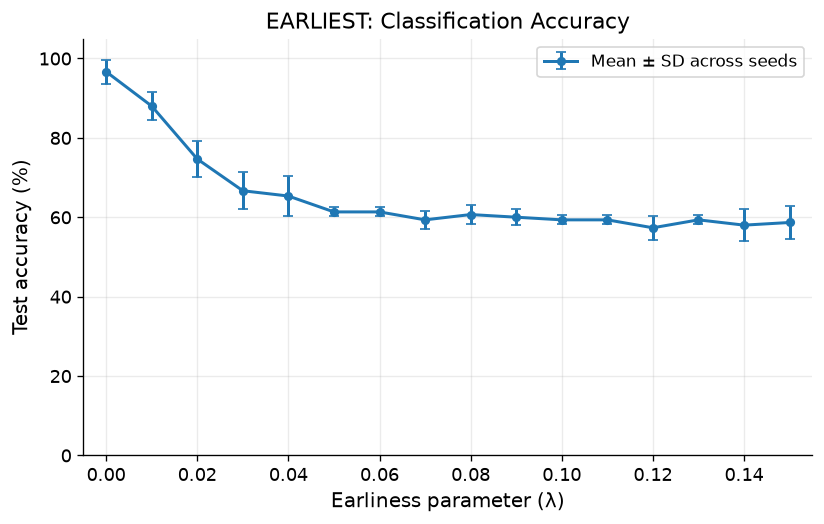

In [17]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.errorbar(
    summary["lambda"],
    summary["accuracy_mean"],
    yerr=summary["accuracy_std"],
    fmt="o-",
    color="tab:blue",
    linewidth=1.8,
    markersize=4.5,
    capsize=3,
    label="Mean ± SD across seeds"
)

ax.set(
    xlabel="Earliness parameter (λ)",
    ylabel="Test accuracy (%)",
    title="EARLIEST: Classification Accuracy",
)
ax.set_xlim(-0.005, 0.155)
ax.set_ylim(0, 105)
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
save_fig(fig, "accuracy_vs_lambda")
plt.show()

3.2 Mean Sequence Observed vs Lambda

Saved: C:\Users\benjo\Documents\Projects\rl_project\EARLIEST\figures\observed_vs_lambda.png


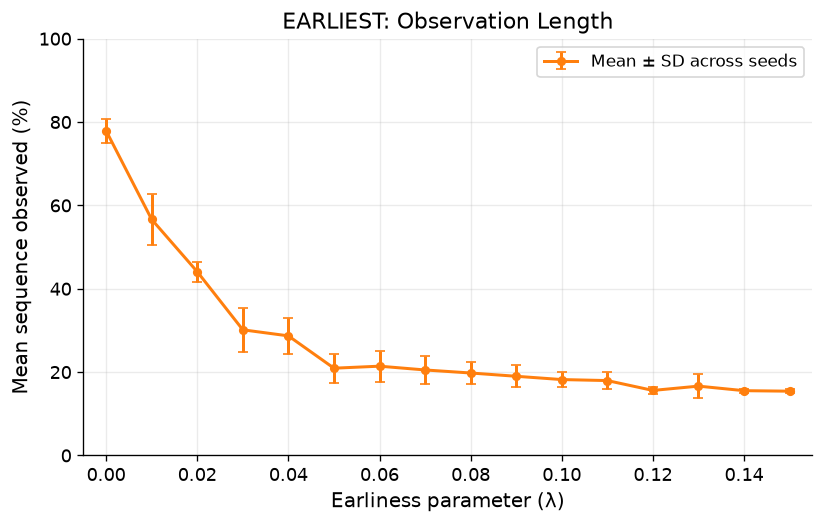

In [19]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.errorbar(
    summary["lambda"],
    summary["observed_mean"],
    yerr=summary["observed_std"],
    fmt="o-",
    color="tab:orange",
    linewidth=1.8,
    markersize=4.5,
    capsize=3,
    label="Mean ± SD across seeds"
)

ax.set(
    xlabel="Earliness parameter (λ)",
    ylabel="Mean sequence observed (%)",
    title="EARLIEST: Observation Length",
)

ax.set_xlim(-0.005, 0.155)
ax.set_ylim(0, 100)
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
save_fig(fig, "observed_vs_lambda")
plt.show()

3.3 Accuracy vs Earliness Trade-off

Saved: C:\Users\benjo\Documents\Projects\rl_project\EARLIEST\figures\accuracy_earliness.png


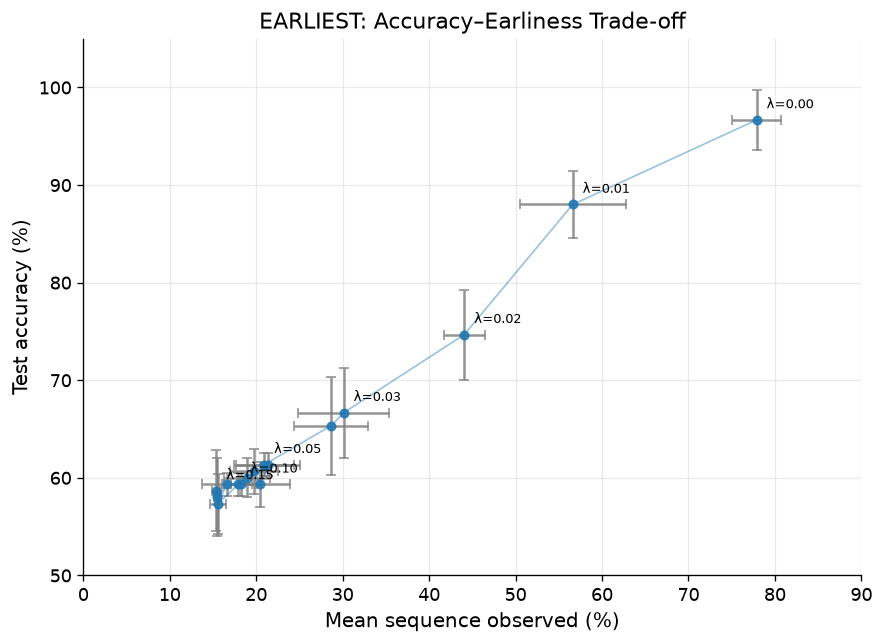

In [21]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))

ax.errorbar(
    summary["observed_mean"],
    summary["accuracy_mean"],
    xerr=summary["observed_std"],
    yerr=summary["accuracy_std"],
    fmt="o",
    linestyle="none",
    color="tab:blue",
    ecolor="gray",
    capsize=3,
    markersize=5,
    alpha=0.85
)

#Connects mean operating points in order of lambda
ax.plot(
    summary["observed_mean"],
    summary["accuracy_mean"],
    color="tab:blue",
    linewidth=1,
    alpha=0.45
)

#Label selected setting to avoid overpopulating
for lam in [0.00, 0.01, 0.02, 0.03, 0.05, 0.10, 0.15]:
    row = summary.loc[np.isclose(summary["lambda"], lam)].iloc[0]

    ax.annotate(
        f"λ={lam:.2f}",
        xy=(row["observed_mean"], row["accuracy_mean"]),
        xytext=(6, 7),
        textcoords="offset points",
        fontsize=8
    )

ax.set(
    xlabel="Mean sequence observed (%)",
    ylabel="Test accuracy (%)",
    title="EARLIEST: Accuracy–Earliness Trade-off"
)

ax.set_xlim(0, 90)
ax.set_ylim(50, 105)
ax.grid(alpha=0.25)

fig.tight_layout()
save_fig(fig, "accuracy_earliness")
plt.show()

3.4 Effects of Random Seeds

Saved: C:\Users\benjo\Documents\Projects\rl_project\EARLIEST\figures\accuracy_by_seed.png


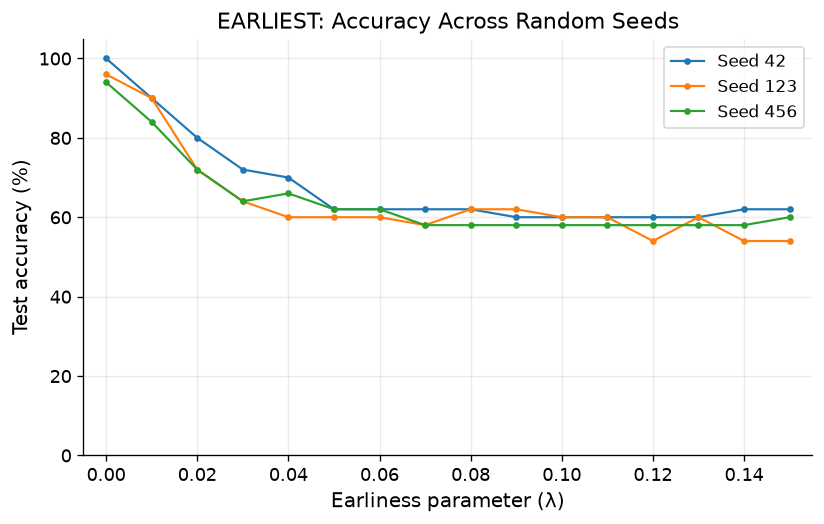

In [22]:
fig, ax = plt.subplots(figsize=(7, 4.5))

for seed, group in analysis_df.groupby("seed"):
    group = group.sort_values("lambda")

    ax.plot(
        group["lambda"],
        group["accuracy_percent"],
        marker="o",
        markersize=3,
        linewidth=1.3,
        label=f"Seed {seed}"
    )

ax.set(
    xlabel="Earliness parameter (λ)",
    ylabel="Test accuracy (%)",
    title="EARLIEST: Accuracy Across Random Seeds"
)
ax.set_xlim(-0.005, 0.155)
ax.set_ylim(0, 105)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
save_fig(fig, "accuracy_by_seed")
plt.show()

3.5 Comparing Specific Operating Points Quantitatively

In [23]:
baseline = summary.loc[
    np.isclose(summary["lambda"], 0.00)
].iloc[0]

candidate = summary.loc[
    np.isclose(summary["lambda"], 0.01)
].iloc[0]

accuracy_difference = (
    candidate["accuracy_mean"] - baseline["accuracy_mean"]
)

observation_difference = (
    candidate["observed_mean"] - baseline["observed_mean"]
)

relative_observation_reduction = (
    (baseline["observed_mean"] - candidate["observed_mean"])
    / baseline["observed_mean"]
    * 100
)

print(f"Accuracy change: {accuracy_difference:.2f} percentage points")
print(f"Observation change: {observation_difference:.2f} percentage points")
print(
    "Relative observation reduction: "
    f"{relative_observation_reduction:.2f}%"
)

Accuracy change: -8.67 percentage points
Observation change: -21.27 percentage points
Relative observation reduction: 27.32%
